**Calcule teoretice (foaia scrisa de mana)**

![WhatsApp Image 2026-10-13 at 13.47.18.jpeg](<attachment:WhatsApp Image 2026-10-13 at 13.47.18.jpeg>)

![WhatsApp Image 2026-10-13 at 13.47.21.jpeg](<attachment:WhatsApp Image 2026-10-13 at 13.47.21.jpeg>)
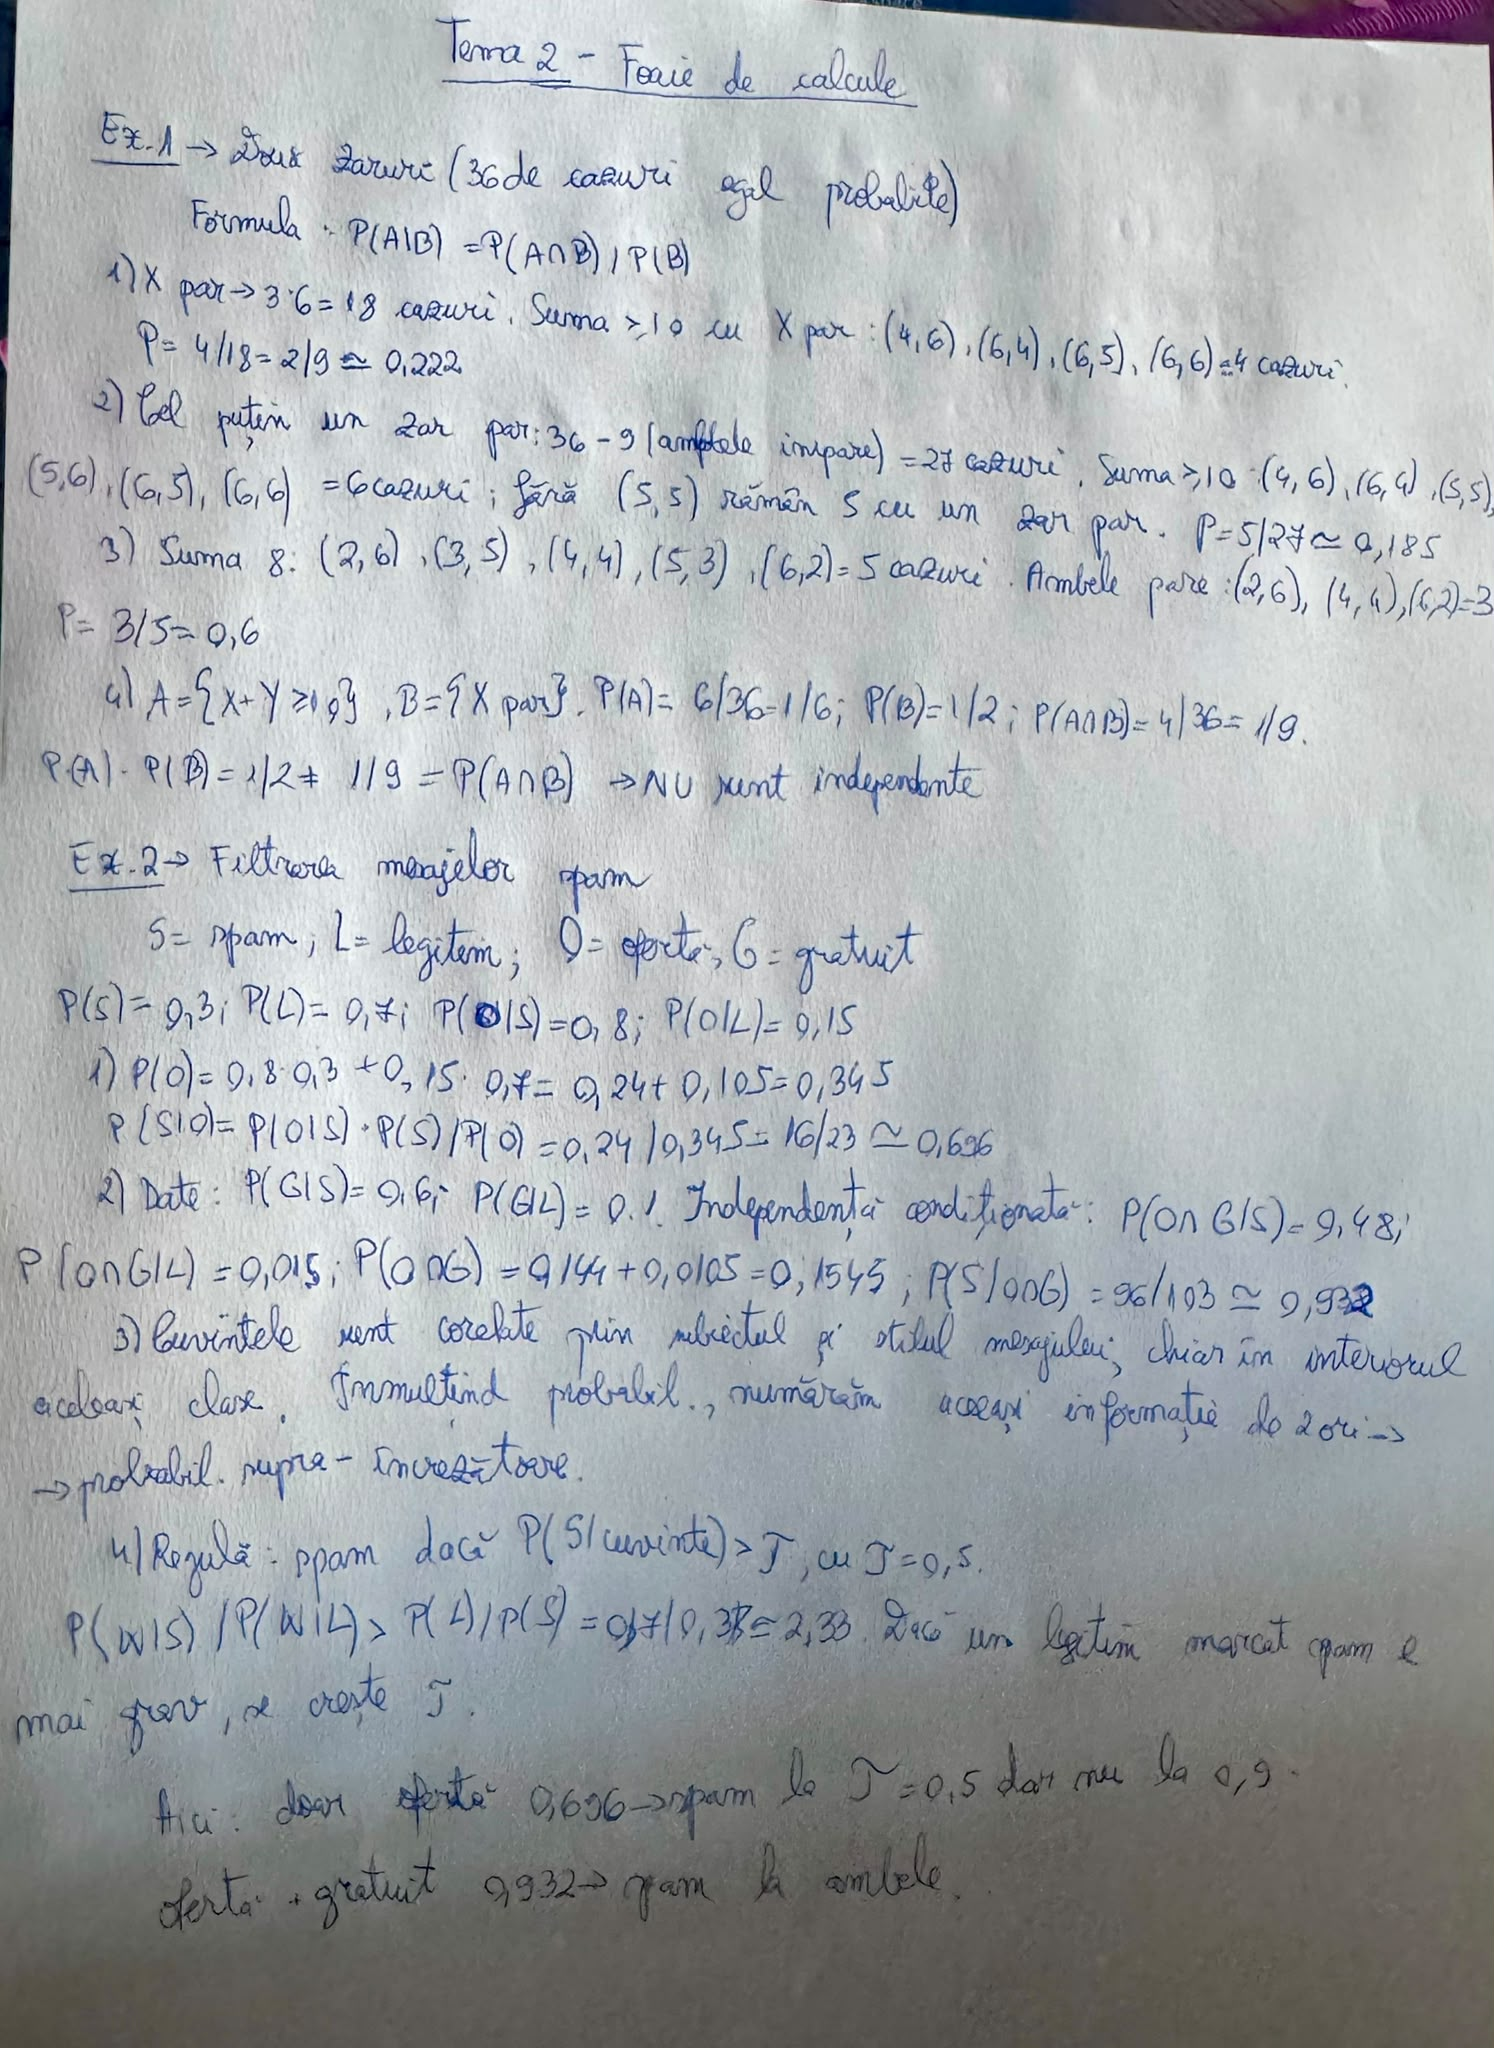
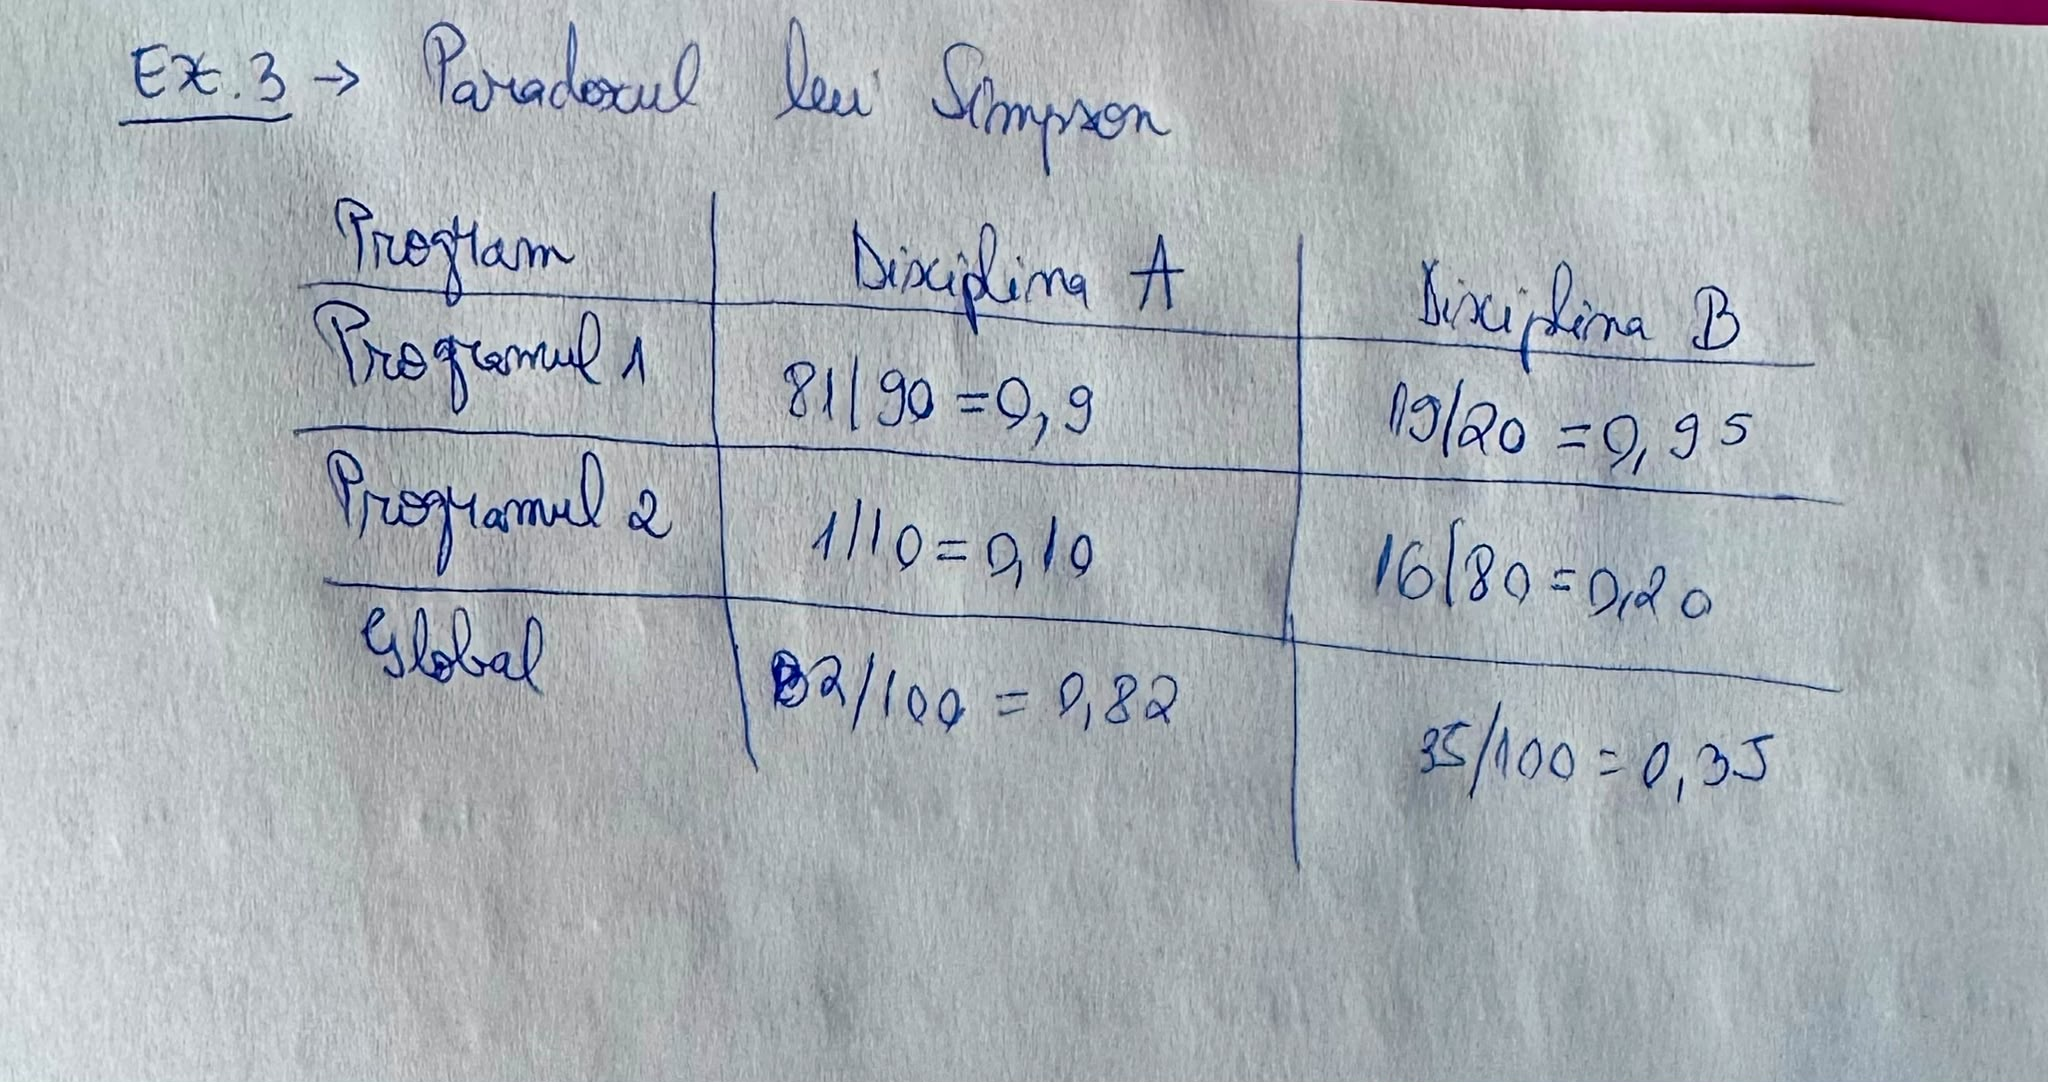

In [1]:
import numpy as np
import pandas as pd

# generator cu seed fix, ca rezultatele sa fie aceleasi la fiecare rulare
rng = np.random.default_rng(42)

**Ex. 1**

1. P(X+Y >= 10 | X par) = 4/18 = 2/9 ≈ 0.222
2. P(X+Y >= 10 | cel putin un zar par) = 5/27 ≈ 0.185
3. P(ambele pare | X+Y = 8) = 3/5 = 0.6
4. P(A) = 1/6, P(B) = 1/2, P(A ∩ B) = 1/9, iar P(A)·P(B) = 1/12 ≠ 1/9, deci A si B nu sunt independente.

Simulare cu 100.000 de aruncari:

In [2]:
n = 100_000
x = rng.integers(1, 7, size=n)
y = rng.integers(1, 7, size=n)
suma = x + y

# evenimente ca masti booleene
x_par = (x % 2 == 0)
y_par = (y % 2 == 0)
suma_mare = (suma >= 10)

# estimare: frecventa relativa in interiorul conditiei
est1 = suma_mare[x_par].mean()
est2 = suma_mare[x_par | y_par].mean()
est3 = (x_par & y_par)[suma == 8].mean()

print("1.", round(est1, 4), "exact", round(2 / 9, 4))
print("2.", round(est2, 4), "exact", round(5 / 27, 4))
print("3.", round(est3, 4), "exact", round(3 / 5, 4))

# punctul 4: comparam P(A si B) cu P(A) * P(B)
p_a = suma_mare.mean()
p_b = x_par.mean()
p_ab = (suma_mare & x_par).mean()
print("4.", "P(A si B) =", round(p_ab, 4), " P(A)*P(B) =", round(p_a * p_b, 4))

1. 0.2241 exact 0.2222
2. 0.1854 exact 0.1852
3. 0.5965 exact 0.6
4. P(A si B) = 0.1119  P(A)*P(B) = 0.0832


**Ex. 2**

S = spam, O = contine "oferta", G = contine "gratuit".

1. P(O) = 0.8·0.3 + 0.15·0.7 = 0.345, deci P(S | O) = 0.8·0.3 / 0.345 = 16/23 ≈ 0.696
2. Cu independenta conditionata: P(O ∩ G | S) = 0.8·0.6 = 0.48 si P(O ∩ G | L) = 0.15·0.1 = 0.015, deci P(S | O ∩ G) = 0.48·0.3 / (0.48·0.3 + 0.015·0.7) = 96/103 ≈ 0.932
3. Ipoteza e nerealista pentru ca cuvintele apar de obicei impreuna, in acelasi tip de mesaj (de exemplu mesaje promotionale), deci nu sunt independente nici in interiorul aceleiasi clase. Inmultirea probabilitatilor numara aceeasi informatie de doua ori si da o probabilitate prea mare.
4. Regula: un mesaj este spam daca P(S | cuvinte) > 0.5. Putem alege un prag mai mare (de exemplu 0.9) daca e mai grav sa pierdem un mesaj legitim decat sa lasam un spam in inbox.

In [3]:
p_s, p_l = 0.3, 0.7
p_o_s, p_o_l = 0.8, 0.15
p_g_s, p_g_l = 0.6, 0.1

# punctul 1: formula lui bayes
p_o = p_o_s * p_s + p_o_l * p_l
p_s_o = p_o_s * p_s / p_o

# punctul 2: independenta conditionata, deci probabilitatile se inmultesc
p_og_s = p_o_s * p_g_s
p_og_l = p_o_l * p_g_l
p_s_og = p_og_s * p_s / (p_og_s * p_s + p_og_l * p_l)

print("P(S | O)      =", round(p_s_o, 4))
print("P(S | O si G) =", round(p_s_og, 4))

# punctul 4: regula de clasificare
def clasifica(p_spam, prag=0.5):
    return "spam" if p_spam > prag else "legitim"

print(clasifica(p_s_o), clasifica(p_s_og))

P(S | O)      = 0.6957
P(S | O si G) = 0.932
spam spam


**Ex. 3**

1. Programul 1: A = 81/90 = 0.90, B = 19/20 = 0.95. Programul 2: A = 1/10 = 0.10, B = 16/80 = 0.20.
2. In ambele programe disciplina B are rata de promovare mai mare.
3. Global: A = 82/100 = 0.82, B = 35/100 = 0.35, deci la nivel global A are rata mai mare.
4. Ordinea se inverseaza pentru ca studentii nu sunt distribuiti la fel: la A, 90 din 100 sunt in Programul 1 (rate mari), iar la B, 80 din 100 sunt in Programul 2 (rate mici). Rata globala este o medie ponderata, deci depinde si de aceste ponderi.
5. P(promovat | A, program) < P(promovat | B, program) pentru fiecare program, dar P(promovat | A) > P(promovat | B). Din formula probabilitatii totale, P(promovat | D) = suma peste programe din P(promovat | D, program) · P(program | D), iar P(program | D) difera mult intre A si B.

In [4]:
date = pd.DataFrame({
    "program": ["Programul 1", "Programul 1", "Programul 2", "Programul 2"],
    "disciplina": ["A", "B", "A", "B"],
    "promovati": [81, 19, 1, 16],
    "evaluati": [90, 20, 10, 80],
})
date["rata"] = date["promovati"] / date["evaluati"]
print(date)

# rata globala pe disciplina
global_ = date.groupby("disciplina")[["promovati", "evaluati"]].sum()
global_["rata"] = global_["promovati"] / global_["evaluati"]
print()
print(global_)

       program disciplina  promovati  evaluati  rata
0  Programul 1          A         81        90  0.90
1  Programul 1          B         19        20  0.95
2  Programul 2          A          1        10  0.10
3  Programul 2          B         16        80  0.20

            promovati  evaluati  rata
disciplina                           
A                  82       100  0.82
B                  35       100  0.35


Extensie: exemplu propriu de paradox Simpson (doua tratamente, doua spitale).

In [5]:
ex = pd.DataFrame({
    "spital": ["Urban", "Urban", "Rural", "Rural"],
    "tratament": ["X", "Y", "X", "Y"],
    "succese": [18, 170, 50, 8],
    "pacienti": [20, 200, 100, 20],
})
ex["rata"] = ex["succese"] / ex["pacienti"]
print(ex)

# pe spital: tratamentul X are rata mai mare in ambele spitale
print()
print(ex.pivot(index="spital", columns="tratament", values="rata"))

# agregat: tratamentul Y pare mai bun
agr = ex.groupby("tratament")[["succese", "pacienti"]].sum()
agr["rata"] = agr["succese"] / agr["pacienti"]
print()
print(agr)

  spital tratament  succese  pacienti  rata
0  Urban         X       18        20  0.90
1  Urban         Y      170       200  0.85
2  Rural         X       50       100  0.50
3  Rural         Y        8        20  0.40

tratament    X     Y
spital              
Rural      0.5  0.40
Urban      0.9  0.85

           succese  pacienti      rata
tratament                             
X               68       120  0.566667
Y              178       220  0.809091


In fiecare spital tratamentul X are rata mai mare (0.90 fata de 0.85 si 0.50 fata de 0.40), dar agregat Y pare mai bun (0.81 fata de 0.57), pentru ca X a fost aplicat mai ales in spitalul Rural, unde cazurile sunt mai grele.